In [1]:
import numpy as np
import pandas as pd
import struct
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt

In [2]:
train = pd.read_csv("fashion-mnist_train.csv")
test = pd.read_csv("fashion-mnist_test.csv")

X_train = train.drop("label", axis=1).values
y_train = train["label"].values

X_test = test.drop("label", axis=1).values
y_test = test["label"].values

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (60000, 784)
Testing: (10000, 784)


In [3]:
X_train = X_train.reshape(-1,28,28)/255.0
X_test = X_test.reshape(-1,28,28)/255.0

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (60000, 28, 28)
Testing: (10000, 28, 28)


In [4]:
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28,28)),

    keras.layers.Dense(128,activation="relu"),
    keras.layers.Dense(64,activation="relu"),
    keras.layers.Dense(10,activation="softmax")
])

C:\Users\Avadhut\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [5]:
model.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.01),
    loss = "sparse_categorical_crossentropy",
    metrics=["accuracy"]
    
)


In [6]:
history = model.fit(
    X_train,y_train,
    epochs=11,
    validation_data=(X_test,y_test)
)

Epoch 1/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.7593 - loss: 0.7276 - val_accuracy: 0.8120 - val_loss: 0.5376
Epoch 2/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8261 - loss: 0.4952 - val_accuracy: 0.8102 - val_loss: 0.5178
Epoch 3/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8411 - loss: 0.4506 - val_accuracy: 0.8436 - val_loss: 0.4399
Epoch 4/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8512 - loss: 0.4233 - val_accuracy: 0.8402 - val_loss: 0.4463
Epoch 5/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8587 - loss: 0.4018 - val_accuracy: 0.8589 - val_loss: 0.4047
Epoch 6/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8627 - loss: 0.3867 - val_accuracy: 0.8628 - val_loss: 0.3905
Epoch 7/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8664 - loss: 0.3742 - val_accuracy: 0.8662 - val_loss: 0.3839
Epoch 8/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8712 - loss: 0.3623 - 

In [7]:
loss, accuracy = model.evaluate(X_test,y_test)

print("Loss", loss)
print("accuracy:", accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8676 - loss: 0.3678  
Loss 0.3677877187728882
accuracy: 0.8676000237464905


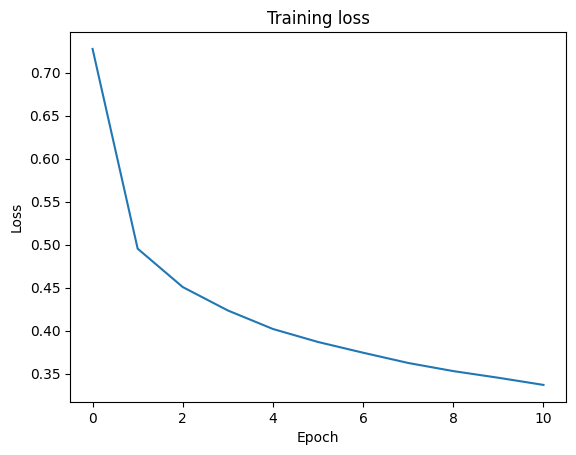

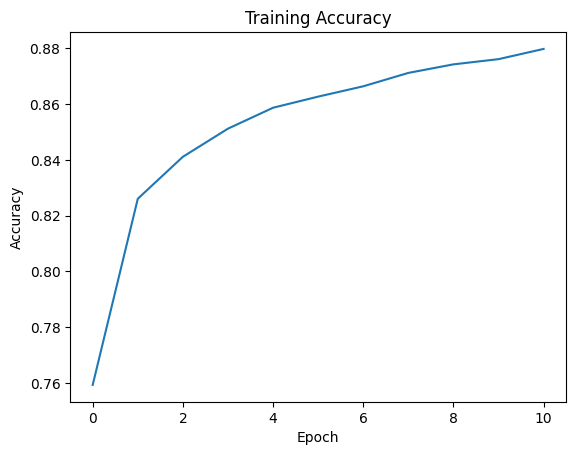

In [9]:
plt.plot(history.history["loss"])
plt.title("Training loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

plt.plot(history.history["accuracy"])
plt.title("Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


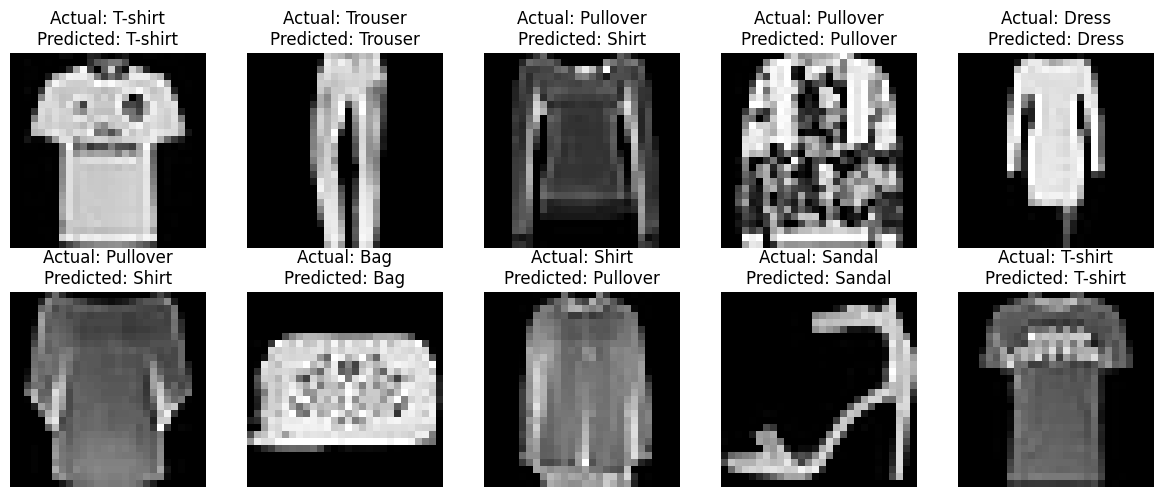

In [13]:
classes = [
    "T-shirt", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle Boot"
]

predictions = model.predict(X_test)

plt.figure(figsize=(12,5))

for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(X_test[i], cmap="gray")
    actual = y_test[i]
    predicted = np.argmax(predictions[i])
    plt.title(f"Actual: {classes[actual]}\nPredicted: {classes[predicted]}")
    plt.axis("off")

plt.tight_layout()
plt.show()
    